# Exploratory Data Analysis

## Project objective

The goal of this project is to forecast the next 24 hourly electricity-consumption values using historical consumption and calendar information. Weather data is not used.

This notebook explores the raw dataset, checks its quality, and constructs an hourly energy-consumption target. The raw source file is read-only and is not modified.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


## Dataset preview

The dataset comes from the UCI Individual Household Electric Power Consumption repository. It contains french individual household electricity measurements recorded at one-minute intervals.

The first few rows are displayed to check the file format, column names, and measurement values before processing the complete dataset.

In [2]:
df_sample = pd.read_csv(
    "../data/raw/household_power_consumption.txt",
    sep=";",
    na_values=["?"]
)

display(df_sample.info())
display(df_sample.head())

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


None

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Data quality and measurement units

The file contains 2,075,259 rows and 9 columns, covering the period from 16 December 2006 to 26 November 2010. The timestamps are valid, unique, and regularly spaced one minute apart.

There are 25,979 rows with missing measurements. In these rows, all seven measurement columns are missing; the date and time are still present.

According to the dataset documentation, `Global_active_power` is measured in kilowatts (kW). For a complete hour, its 60 one-minute readings can be converted to hourly energy in kilowatt-hours (kWh) by summing them and dividing by 60.

## Constructing the hourly target

The forecasting target is the household's total hourly energy consumption in kWh. It is derived from `Global_active_power`, which represents total active power; the sub-metering columns are not added to it.

A target is calculated only when all 60 one-minute power readings for that hour are available. Hours with incomplete measurements are left missing rather than estimated, so partial sums are not mistaken for complete hourly consumption.

In [3]:
# Loading the raw data without modifying the source file.
raw_path = Path("../data/raw/household_power_consumption.txt")
df = pd.read_csv(raw_path, sep=";", na_values=["?"])

# Combining the date and time columns into one timestamp.
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="raise",
)

# Grouping minute-level active power readings by hour.
power_by_minute = df.set_index("timestamp")["Global_active_power"]
hourly_groups = power_by_minute.groupby(
    power_by_minute.index.floor("h"),
    sort=True,
)

# Converting kW readings to hourly energy in kWh.
hourly = pd.DataFrame(
    {
        "timestamp_count": hourly_groups.size(),
        "valid_minutes": hourly_groups.count(),
        "target_kwh": hourly_groups.sum(min_count=60) / 60,
    }
)

# Keeping a target only when all 60 minute readings are available.
complete_hours = (
    hourly["timestamp_count"].eq(60)
    & hourly["valid_minutes"].eq(60)
)
hourly.loc[~complete_hours, "target_kwh"] = pd.NA

# Displaying checks and a sample of valid hourly targets.
print(f"Hourly time slots: {len(hourly):,}")
print(f"Valid targets (60/60 minutes): {hourly['target_kwh'].notna().sum():,}")
print(f"Missing targets: {hourly['target_kwh'].isna().sum():,}")
print(
    "Partial hours at the start or end of the file: "
    f"{hourly['timestamp_count'].lt(60).sum():,}"
)
print(
    "Hours with 60 timestamps but missing power readings: "
    f"{(hourly['timestamp_count'].eq(60) & hourly['valid_minutes'].lt(60)).sum():,}"
)

display(
    hourly.loc[
        hourly["target_kwh"].notna(),
        ["valid_minutes", "target_kwh"],
    ].head()
)

Hourly time slots: 34,589
Valid targets (60/60 minutes): 34,085
Missing targets: 504
Partial hours at the start or end of the file: 2
Hours with 60 timestamps but missing power readings: 502


,valid_minutes,target_kwh
timestamp,,
2006-12-16 18:00:00,60,3.632200
2006-12-16 19:00:00,60,3.400233
2006-12-16 20:00:00,60,3.268567
2006-12-16 21:00:00,60,3.056467
2006-12-16 22:00:00,60,2.200133



### Aggregation results

The dataset produces 34,589 hourly time slots. Of these, 34,085 have all 60 power readings and a valid hourly target. The other 504 targets are missing: 502 hours contain missing power readings, and 2 time slots at the beginning or end of the dataset are partial hours.

No missing hourly values are interpolated. 

## Hourly consumption over time

This plot provides an overview of hourly energy consumption across the full dataset. It can help reveal broad changes and unusually high values, but the long time range makes short-term daily patterns difficult to distinguish.

Hourly slots: 34,589
Period: 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Valid hourly targets: 34,085
Missing hourly targets: 504
Intervals exactly one hour apart: 34,588
Other time intervals: 0


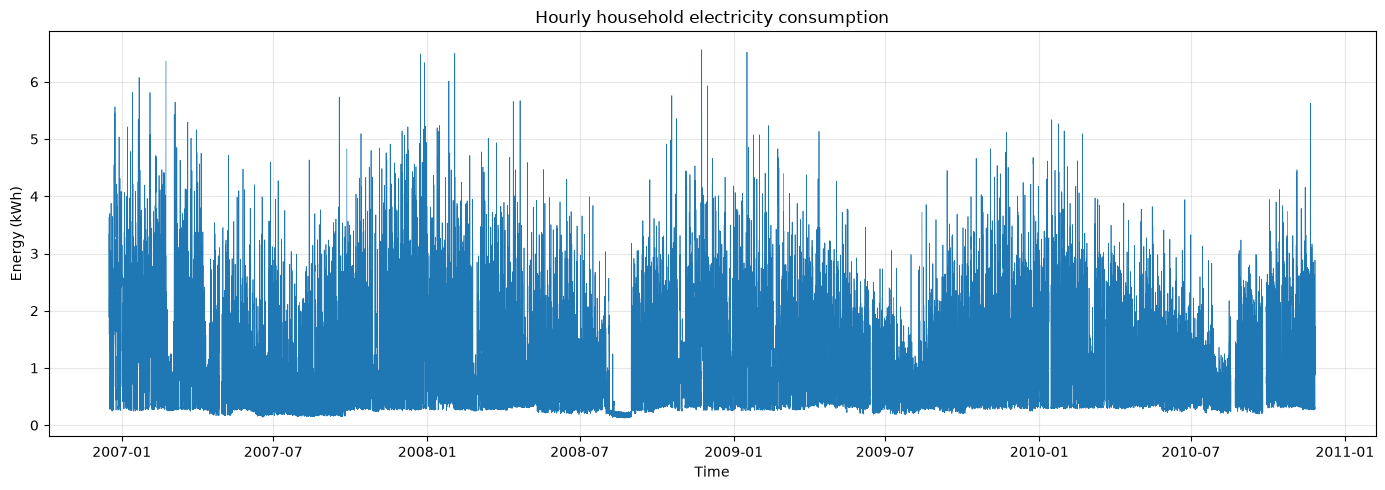

In [4]:
# Making sure the timestamp is a column, whether it is currently a column or the index.
hourly_eda = hourly.copy()

if "timestamp" not in hourly_eda.columns:
    hourly_eda = hourly_eda.rename_axis("timestamp").reset_index()

hourly_eda["timestamp"] = pd.to_datetime(hourly_eda["timestamp"])
hourly_eda = hourly_eda.sort_values("timestamp")

# Checking the time range, target availability, and hourly continuity.
print(f"Hourly slots: {len(hourly_eda):,}")
print(f"Period: {hourly_eda['timestamp'].min()} to {hourly_eda['timestamp'].max()}")
print(f"Valid hourly targets: {hourly_eda['target_kwh'].notna().sum():,}")
print(f"Missing hourly targets: {hourly_eda['target_kwh'].isna().sum():,}")

time_deltas = hourly_eda["timestamp"].diff().dropna()
print(f"Intervals exactly one hour apart: {(time_deltas == pd.Timedelta(hours=1)).sum():,}")
print(f"Other time intervals: {(time_deltas != pd.Timedelta(hours=1)).sum():,}")

# Ploting the hourly energy series; missing targets remain visible as gaps.
plt.figure(figsize=(14, 5))
plt.plot(hourly_eda["timestamp"], hourly_eda["target_kwh"], linewidth=0.5)
plt.title("Hourly household electricity consumption")
plt.xlabel("Time")
plt.ylabel("Energy (kWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Initial observations

Hourly consumption varies substantially, with occasional peaks above 6 kWh. The full-period plot is useful for an overview, but its dense timeline does not establish a clear annual seasonal pattern on its own.

Gaps in the plotted series correspond to hours without a valid target. They are intentionally left missing rather than filled with estimated values.

## Calendar patterns

The next plots compare average hourly consumption by hour of day, day of week, and weekday-hour combination. These summaries help explore whether calendar information may be useful for forecasting.

Only hours with a valid target are included. The averages describe this dataset and should not automatically be interpreted as stable patterns for every year.

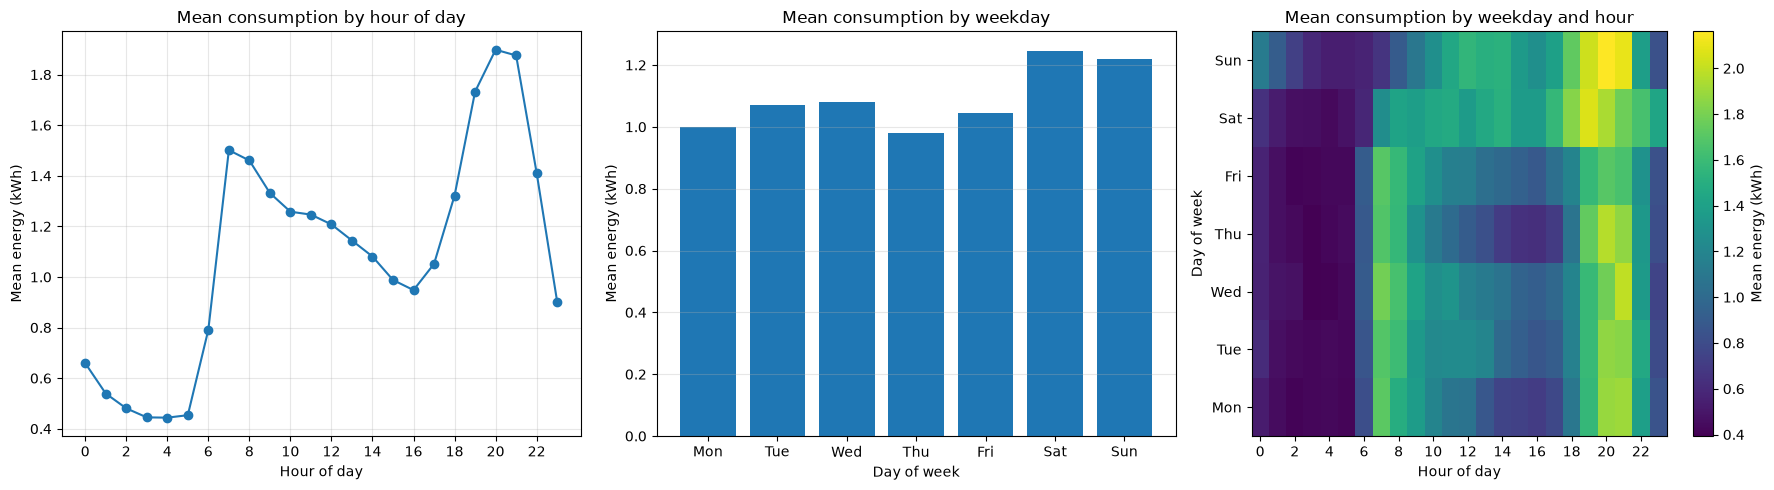

Valid hourly targets by weekday:
weekday
Mon    4890
Tue    4906
Wed    4886
Thu    4879
Fri    4911
Sat    4798
Sun    4815
Name: count, dtype: int64


In [5]:
# Using only hours with a valid target.
calendar_data = hourly_eda.dropna(subset=["target_kwh"]).copy()
calendar_data["hour_of_day"] = calendar_data["timestamp"].dt.hour
calendar_data["weekday"] = calendar_data["timestamp"].dt.dayofweek

# Calculating the mean consumption and sample count for each calendar group.
hourly_profile = calendar_data.groupby("hour_of_day")["target_kwh"].agg(
    ["mean", "count"]
)
weekday_profile = calendar_data.groupby("weekday")["target_kwh"].agg(
    ["mean", "count"]
)

# Calculating mean consumption for each weekday-hour combination.
weekday_hour_mean = calendar_data.pivot_table(
    values="target_kwh",
    index="weekday",
    columns="hour_of_day",
    aggfunc="mean",
).reindex(index=range(7), columns=range(24))

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(hourly_profile.index, hourly_profile["mean"], marker="o")
axes[0].set_title("Mean consumption by hour of day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean energy (kWh)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, alpha=0.3)

axes[1].bar(weekday_profile.index, weekday_profile["mean"])
axes[1].set_title("Mean consumption by weekday")
axes[1].set_xlabel("Day of week")
axes[1].set_ylabel("Mean energy (kWh)")
axes[1].set_xticks(range(7), weekday_names)
axes[1].grid(axis="y", alpha=0.3)

image = axes[2].imshow(
    weekday_hour_mean,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
)
axes[2].set_title("Mean consumption by weekday and hour")
axes[2].set_xlabel("Hour of day")
axes[2].set_ylabel("Day of week")
axes[2].set_xticks(range(0, 24, 2))
axes[2].set_yticks(range(7), weekday_names)
fig.colorbar(image, ax=axes[2], label="Mean energy (kWh)")

plt.tight_layout()
plt.show()

# Checking how many observations support each average.
print("Valid hourly targets by weekday:")
print(weekday_profile["count"].rename(index=dict(enumerate(weekday_names))))

### Calendar-pattern observations

- **Hour of day:** Mean consumption is lowest overnight, at roughly 0.4–0.5 kWh between 2:00 and 5:00. It rises sharply in the morning, reaching about 1.5 kWh around 7:00–8:00, then generally decreases through the afternoon. A second, higher peak appears around 19:00–20:00, at approximately 1.9 kWh.
- **Day of week:** Saturday and Sunday have the highest average consumption, at roughly 1.2 kWh. Thursday has the lowest average, just under 1.0 kWh; the other weekdays are around 1.0–1.1 kWh.
- **Weekday and hour:** The heatmap shows a recurring evening rise around 19:00–21:00 across the week. The morning increase around 7:00–8:00 is also visible, though its intensity varies by day. Weekend consumption appears higher during parts of the day, especially in the evening.
- **Caution:** These are descriptive averages across the full dataset. They do not show whether the patterns are stable from year to year, and they should not be interpreted as causal. Their forecasting value must be assessed with chronological validation.

In [6]:
# Preparing a table with timestamp as a column.
gap_check = hourly.copy()

if "timestamp" not in gap_check.columns:
    gap_check = gap_check.rename_axis("timestamp").reset_index()

gap_check = gap_check.sort_values("timestamp").reset_index(drop=True)

# Identifying consecutive runs of missing hourly targets.
is_missing = gap_check["target_kwh"].isna()
run_id = is_missing.ne(is_missing.shift()).cumsum()

missing_runs = (
    gap_check.loc[is_missing]
    .assign(run_id=run_id[is_missing].to_numpy())
    .groupby("run_id")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        missing_hours=("timestamp", "size"),
    )
    .sort_values("missing_hours", ascending=False)
)

print(f"Number of missing-target runs: {len(missing_runs):,}")
print("Longest missing-target runs:")
display(missing_runs.head(10))

Number of missing-target runs: 70
Longest missing-target runs:


,start,end,missing_hours
run_id,,,
133,2010-08-17 21:00:00,2010-08-22 21:00:00,121
135,2010-09-25 03:00:00,2010-09-28 19:00:00,89
15,2007-04-28 00:00:00,2007-04-30 14:00:00,63
95,2009-06-13 00:00:00,2009-06-15 07:00:00,56
113,2010-01-12 14:00:00,2010-01-14 19:00:00,54
121,2010-03-20 03:00:00,2010-03-21 13:00:00,35
99,2009-08-13 05:00:00,2009-08-13 19:00:00,15
29,2007-07-15 16:00:00,2007-07-15 19:00:00,4
65,2008-10-25 10:00:00,2008-10-25 11:00:00,2


### Missing-target intervals

The 504 missing hourly targets occur in 70 separate intervals; they are not all isolated missing hours. The longest intervals contain 121 hourly slots from 17 August 2010 at 21:00 to 22 August 2010 at 21:00, 89 slots from 25 September 2010 at 03:00 to 28 September 2010 at 19:00, and 63 slots from 28 April 2007 at 00:00 to 30 April 2007 at 14:00.

These extended data gaps should not be filled by interpolation for the forecasting analysis. Training and evaluation windows must be selected so that missing targets are not treated as observed consumption.

## Exploratory chronological partition (not final evaluation)

An initial 80/20 chronological partition is retained only to define the earlier training segment used for the time-series diagnostics below. It is not the split used by the reusable forecasting pipeline, and this notebook no longer compares models or reports forecast scores.

The final workflow uses chronological training, validation, and test periods (70/15/15); model selection uses validation, and the final test results are reported separately in `reports/forecasting_results.md`. The dataset and an earlier overlapping holdout were examined during exploration, so the final test is not fully blind.

In [7]:
# Preparing the hourly table with timestamp as a column.
split_data = hourly.copy()

if "timestamp" not in split_data.columns:
    split_data = split_data.rename_axis("timestamp").reset_index()

split_data["timestamp"] = pd.to_datetime(split_data["timestamp"])
split_data = split_data.sort_values("timestamp").reset_index(drop=True)

# Retaining an exploratory 80/20 boundary only for the training diagnostics below.
split_position = int(len(split_data) * 0.8)
cutoff = split_data.loc[split_position, "timestamp"]
train = split_data.loc[split_data["timestamp"] < cutoff].copy()

print(f"Exploratory diagnostic cutoff: {cutoff}")
print(f"Diagnostic training segment: {train['timestamp'].min()} to {train['timestamp'].max()}")
print(f"Diagnostic training slots: {len(train):,}")
print(f"Valid diagnostic targets: {train['target_kwh'].notna().sum():,}")
print(f"Missing diagnostic targets: {train['target_kwh'].isna().sum():,}")

Exploratory diagnostic cutoff: 2010-02-11 16:00:00
Diagnostic training segment: 2006-12-16 17:00:00 to 2010-02-11 15:00:00
Diagnostic training slots: 27,671
Valid diagnostic targets: 27,420
Missing diagnostic targets: 251


## Stationarity analysis

Stationarity tests help assess whether a time series has a stable statistical level over time. The Augmented Dickey-Fuller (ADF) test has a unit-root null hypothesis, while the KPSS test has a stationarity null hypothesis.

The tests are applied only to a continuous segment of valid hourly targets from the training period. Missing hours are not removed and interpolated, because doing so would make observations separated by gaps appear adjacent. The test period is not used.

These tests do not by themselves establish that the series is fully stationary or remove daily and weekly seasonal patterns. Their results are interpreted alongside the rolling mean and standard deviation.

Continuous training observations: 1,311
Sample period: 2008-08-31 19:00:00 to 2008-10-25 09:00:00


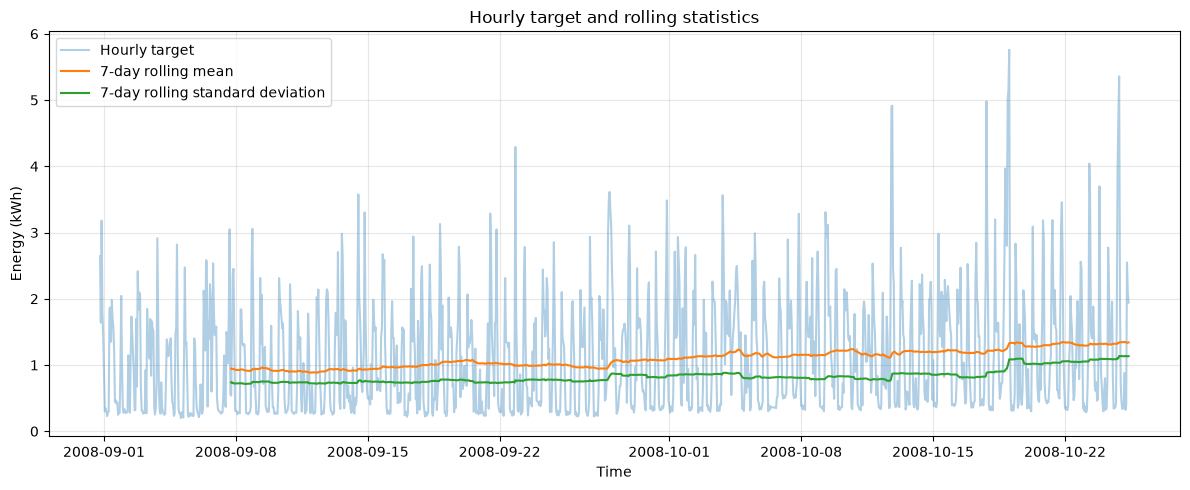

ADF statistic: -5.2849
ADF p-value: 5.883e-06
KPSS statistic: 1.7207
KPSS p-value: 0.01


/tmp/ipykernel_12687/1790412865.py:46: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(stationarity_sample, regression="c", autolag="AIC")
/tmp/ipykernel_12687/1790412865.py:47: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(stationarity_sample, regression="c", nlags="auto")
/tmp/ipykernel_12687/1790412865.py:47: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later,

In [8]:
# Selecting valid training targets and splitting them into uninterrupted segments.
training_targets = (
    split_data.loc[split_data["timestamp"] < cutoff]
    .set_index("timestamp")["target_kwh"]
    .sort_index()
)
valid_training_targets = training_targets.dropna()

segment_ids = (
    valid_training_targets.index.to_series()
    .diff()
    .ne(pd.Timedelta(hours=1))
    .cumsum()
)
continuous_segments = [
    segment
    for _, segment in valid_training_targets.groupby(segment_ids)
]

stationarity_sample = max(continuous_segments, key=len)

print(f"Continuous training observations: {len(stationarity_sample):,}")
print(
    f"Sample period: {stationarity_sample.index.min()} "
    f"to {stationarity_sample.index.max()}"
)

# Comparing rolling statistics over a seven-day window.
rolling_window = 24 * 7
rolling_mean = stationarity_sample.rolling(rolling_window).mean()
rolling_std = stationarity_sample.rolling(rolling_window).std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(stationarity_sample.index, stationarity_sample, alpha=0.35, label="Hourly target")
ax.plot(rolling_mean.index, rolling_mean, label="7-day rolling mean")
ax.plot(rolling_std.index, rolling_std, label="7-day rolling standard deviation")
ax.set_title("Hourly target and rolling statistics")
ax.set_xlabel("Time")
ax.set_ylabel("Energy (kWh)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Running ADF and KPSS tests on the uninterrupted training segment.
adf_result = adfuller(stationarity_sample, regression="c", autolag="AIC")
kpss_result = kpss(stationarity_sample, regression="c", nlags="auto")

print(f"ADF statistic: {adf_result[0]:.4f}")
print(f"ADF p-value: {adf_result[1]:.4g}")
print(f"KPSS statistic: {kpss_result[0]:.4f}")
print(f"KPSS p-value: {kpss_result[1]:.4g}")

### Preliminary stationarity results

The tests were applied to the longest uninterrupted segment of valid training targets.

The ADF test returned a statistic of -5.2849 and a p-value of 5.883e-06, so its unit-root null hypothesis is rejected at the 5% level. The KPSS test returned a statistic of 1.7207 and a reported p-value of 0.01, so its null hypothesis of stationarity around a constant level is also rejected. The KPSS warning indicates that 0.01 is the lower bound reported by its p-value table; the p-value is at most 0.01.

Together, these results do not support stationarity around a constant level in this segment. They do not yet determine whether a deterministic trend could account for the result. The rising rolling mean and the series' seasonal patterns should also be considered. These tests concern one continuous training segment, not the entire series.

In [9]:
# Re-running the tests allowing for a deterministic linear trend.
adf_trend_result = adfuller(
    stationarity_sample,
    regression="ct",
    autolag="AIC",
)
kpss_trend_result = kpss(
    stationarity_sample,
    regression="ct",
    nlags="auto",
)

print(f"ADF with trend statistic: {adf_trend_result[0]:.4f}")
print(f"ADF with trend p-value: {adf_trend_result[1]:.4g}")
print(f"KPSS with trend statistic: {kpss_trend_result[0]:.4f}")
print(f"KPSS with trend p-value: {kpss_trend_result[1]:.4g}")

ADF with trend statistic: -6.6498
ADF with trend p-value: 8.616e-08
KPSS with trend statistic: 0.0151
KPSS with trend p-value: 0.1


/tmp/ipykernel_12687/3611256763.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_trend_result = adfuller(
/tmp/ipykernel_12687/3611256763.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_trend_result = kpss(
/tmp/ipykernel_12687/3611256763.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True t

### Stationarity results with a deterministic trend

For the longest uninterrupted segment of valid training targets, the ADF test with a linear trend returned a p-value of 8.616e-08. Its unit-root null hypothesis is rejected at the 5% level.

The KPSS test with a linear trend returned a p-value reported as 0.1. This is the upper bound of the test's lookup table, so the stationarity null hypothesis is not rejected at the 5% level.

Together, these results are compatible with trend-stationarity for this segment: the series is not supported as stationary around a constant level, but a deterministic linear trend may account for the non-stationarity detected by the constant-level tests. This conclusion is preliminary; daily and weekly seasonal patterns are not ruled out, and the tests cover only one uninterrupted training segment.

## Autocorrelation analysis

The ACF and PACF show how hourly targets relate to earlier observations. We examine up to 168 lags to look for daily (24-hour) and weekly (168-hour) dependence.

To reduce the influence of the deterministic linear trend identified in the stationarity analysis, the plots use the detrended training segment. The segment is continuous and contains no imputed values.

ACF and PACF are diagnostic tools, not automatic model-selection rules. Peaks near seasonal lags can indicate temporal dependence worth considering in later forecasting models.

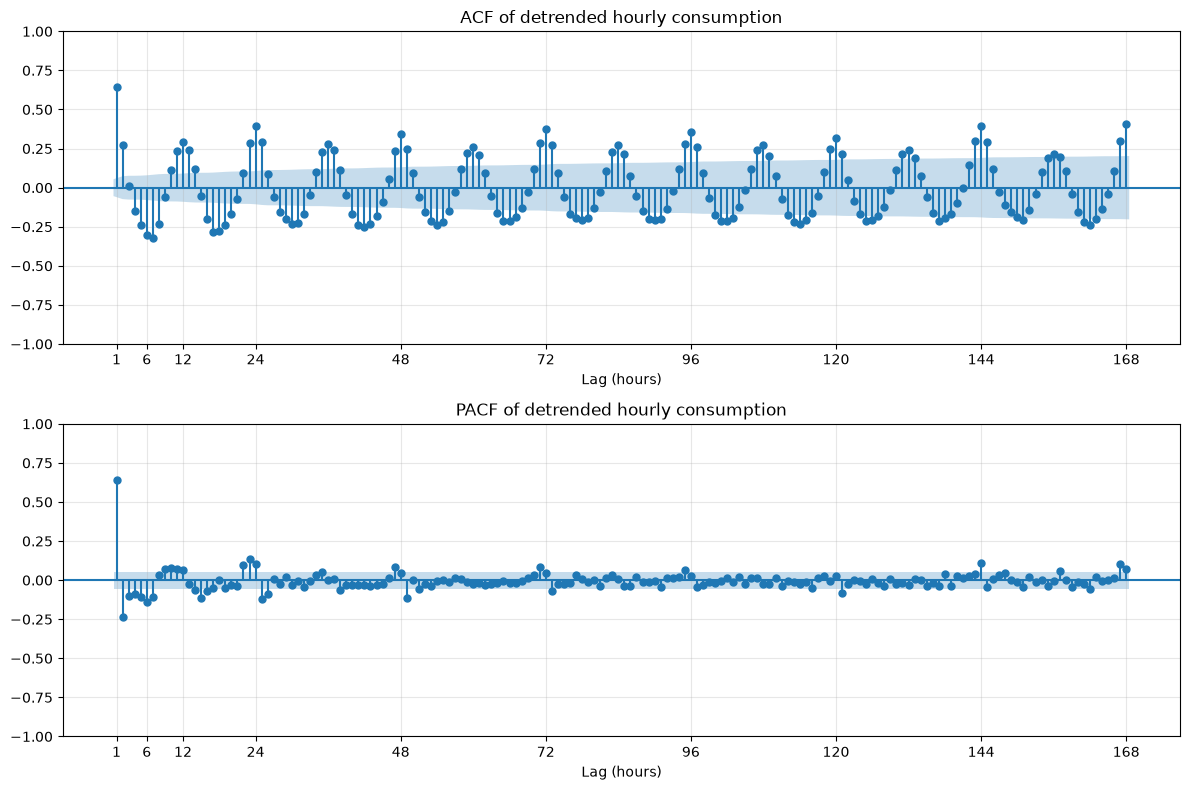

In [10]:
# Remove a linear trend from the continuous training segment.
time_steps = np.arange(len(stationarity_sample))
trend_coefficients = np.polyfit(time_steps, stationarity_sample.to_numpy(), deg=1)
linear_trend = np.polyval(trend_coefficients, time_steps)
detrended_sample = stationarity_sample - linear_trend

# Plot autocorrelation up to one week of hourly lags.
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(detrended_sample, lags=168, zero=False, ax=axes[0])
axes[0].set_title("ACF of detrended hourly consumption")
axes[0].set_xlabel("Lag (hours)")
axes[0].set_xticks([1, 6, 12, 24, 48, 72, 96, 120, 144, 168])
axes[0].grid(True, alpha=0.3)

plot_pacf(detrended_sample, lags=168, zero=False, method="ywm", ax=axes[1])
axes[1].set_title("PACF of detrended hourly consumption")
axes[1].set_xlabel("Lag (hours)")
axes[1].set_xticks([1, 6, 12, 24, 48, 72, 96, 120, 144, 168])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### ACF and PACF observations

The ACF shows strong short-term dependence, especially at lag 1, and recurring peaks around 24-hour intervals. Peaks are also visible at multiples of 24 hours, with a positive correlation at lag 168. This is consistent with daily and weekly temporal structure in the detrended training segment.

The PACF is dominated by lag 1, with additional significant spikes at some short and seasonal lags. These plots describe autocorrelation patterns; they do not determine model parameters automatically.

The analysis uses one uninterrupted training segment after removing a linear trend. It does not establish that the entire series is stationary, and the confidence bands should be interpreted cautiously across many lags.